# 02 · Student alignment and progressive pruning (DDP, 2 GPUs)
1. **Align (28 layers)**: the frozen student + LoRA r=16 on every decoder linear + a linear head 1024→256 learns to
   put its query vector on the teacher's vector of the same query: L2 = ||s − t||² = 2 − 2·cos. Only the adapter trains.
2. **Prune 28 → 14 → 7**: each stage merges the previous weights, keeps evenly spaced decoder layers (first and last
   always), then fine-tunes **every weight** + head with the same L2 on the same queries (re-alignment).

Each stage is its own checkpoint dir (`aligned/`, `prog_l14/`, `prog_l7/`, each with `final/`) and its own row.
Step checkpoints keep the last `keep_last`; re-running resumes and a finished stage is skipped.

Input: `01`. Output (attach to `03`, `04`): `runs/<mode>/{aligned, prog_l14, prog_l7}/`, `runs/<mode>/metrics.json`.

In [1]:
from kaggle_secrets import UserSecretsClient
secret_label = "HF_TOKEN"
secret_value = UserSecretsClient().get_secret(secret_label)

In [2]:
# setup: clone/pull the repo on Kaggle, put it on sys.path, install what's missing (re-run to pull latest code)
import os, sys, importlib.util
REPO_URL = "https://github.com/pyther-hub/hlm-poc.git"
ON_KAGGLE = os.path.exists("/kaggle/working")
REPO = "/kaggle/working/hlm-poc" if ON_KAGGLE else os.path.abspath("..")
if ON_KAGGLE:
    if not os.path.exists(REPO):
        !git clone -q {REPO_URL} {REPO}
    else:
        !git -C {REPO} pull -q
sys.path.insert(0, REPO)

# HF token (higher rate limits, faster downloads). Kaggle: Add-ons -> Secrets -> add "HF_TOKEN", attach to notebook.
# Spawned workers inherit os.environ. Locally: export HF_TOKEN or `huggingface-cli login`.
if ON_KAGGLE and "HF_TOKEN" not in os.environ:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print(f"HF_TOKEN secret not found ({type(e).__name__}): downloads stay unauthenticated")

import transformers
from packaging.version import Version
if Version(transformers.__version__) < Version("4.56"):  # Qwen3 + the dtype= kwarg
    !pip install -q -U "transformers>=4.56"
    print("transformers upgraded: restart the kernel, then re-run this cell")
for pkg in ("datasets", "pyarrow", "accelerate"):
    if importlib.util.find_spec(pkg) is None:
        !pip install -q {pkg}


## Control panel

In [3]:
import os
import shutil
import torch
from model import get_device
from teacher import TEACHER_DEFAULTS as T

DEBUG = False    # use the same value as in 01
NPROCS = 2

# --- paths. On Kaggle, earlier notebooks' outputs are attached as inputs (read only); set the slugs to yours.
#     Off Kaggle everything lives under the repo, so every IN_* is the same dir.
ROOT = "/kaggle/working" if ON_KAGGLE else REPO
MODE = "debug" if DEBUG else "full"
KAGGLE_IN = "/kaggle/input/datasets/tensorpanda231"
IN_01 = f"{KAGGLE_IN}/corpus-teacher-embd" if ON_KAGGLE else REPO
DATA_PATH = f"{IN_01}/cache/{MODE}/data.json"
EMB_DIR = f"{IN_01}/cache/{MODE}/emb/teacher"
RUN_DIR = f"{ROOT}/runs/{MODE}"
PREV_METRICS = f"{IN_01}/runs/{MODE}/metrics.json"

# --- stage 1: alignment of the 28-layer student (align.ALIGN_DEFAULTS; unknown keys raise)
ALIGN = dict(model="Qwen/Qwen3-Embedding-0.6B",   # student base, frozen
             dim=T["dim"],                        # head output = teacher index dim
             lora_rank=16, lora_alpha=32, lora_dropout=0.05,
             lora_targets=("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"),
             query_prefix="", max_query_len=32,   # student queries: no prompt
             loss="l2", loss_kwargs={},           # ||s - t||^2 = 2 - 2 cos between unit vectors
             lr=2e-4, head_lr=1e-3, weight_decay=0.0, warmup_ratio=0.05,
             epochs=1, batch_size=128,            # per GPU; global batch = batch_size * NPROCS
             grad_clip=1.0, amp=True, seed=0,
             log_every=20, eval_every=200, save_every=500, keep_last=2,
             data_path=DATA_PATH, teacher_emb_dir=EMB_DIR, out_dir=f"{RUN_DIR}/aligned")

# --- stages 2+: pruning, full fine-tune with L2 (prune.PRUNE_DEFAULTS; init / n_layers / out_dir set per stage)
STAGES = (14, 7)                                   # 28 -> 14 -> 7, each from the previous stage
PRUNE = dict(ffn_keep=1.0,                         # layers only: every kept layer keeps its full FFN
             dim=T["dim"], query_prefix="", max_query_len=32,
             lr=2e-5, head_lr=1e-4, weight_decay=0.0, warmup_ratio=0.05,
             epochs=1, batch_size=64,              # per GPU
             grad_clip=1.0, amp=True, seed=0,
             log_every=20, eval_every=200, save_every=500, keep_last=2,
             data_path=DATA_PATH, teacher_emb_dir=EMB_DIR)

# --- evaluation (evaluation.evaluate_model kwargs): student queries vs the frozen teacher corpus, top 100
EVAL = dict(splits=("val", "test"), dim=T["dim"], max_query_len=32, query_prefix="", device=get_device(), dtype="fp16")
LATENCY = dict(n_queries=2000, batch_sizes=(1, 32))

if DEBUG:
    for cfg in (ALIGN, PRUNE):
        cfg.update(log_every=5, eval_every=20, save_every=20)
    LATENCY.update(n_queries=200)

## 1 · Check inputs
Teacher vectors valid (finite, unit norm, `data.json` order) for the corpus, val/test and the alignment queries.

In [4]:
from data import load_emb, load_json
from evaluation import check_emb, load_index

# rows accumulate across notebooks: start from the previous notebook's metrics.json (copied once)
os.makedirs(RUN_DIR, exist_ok=True)
if not os.path.exists(f"{RUN_DIR}/metrics.json") and os.path.exists(PREV_METRICS):
    shutil.copy(PREV_METRICS, f"{RUN_DIR}/metrics.json")
data = load_json(DATA_PATH)
index = load_index(data, EMB_DIR, ("val", "test"))   # (teacher docs, {split: teacher queries})
emb, ids = load_emb(EMB_DIR, "align")
check_emb(emb, ids, data["align"]["ids"], "align")
print(f"align {emb.shape}: {len(ids) // (ALIGN['batch_size'] * NPROCS)} align steps, "
      f"{len(ids) // (PRUNE['batch_size'] * NPROCS)} steps per prune stage")




[eval] index ok: corpus (299985, 256), val (5000, 256), test (5000, 256)
align (200000, 256): 781 align steps, 1562 steps per prune stage


## 2 · Align the 28-layer student
Rank r takes its slice of every global batch; DDP averages the adapter gradients. Val L2 / cos / nDCG@10 are logged
every `eval_every` steps.

In [5]:
from align import align_main
from run_exp import train_once

runs = {"aligned": train_once(align_main, ALIGN, NPROCS)}

[rank1] joined process group on cuda:1 (14.5/14.6 GB free)
[rank0] joined process group on cuda:0 (14.5/14.6 GB free)
[rank0] loading Qwen/Qwen3-Embedding-0.6B
[rank1] waiting for rank 0 to load the model


Loading weights: 100%|██████████| 310/310 [00:00<00:00, 472.58it/s]


[rank0] model loaded on cuda:0 (12.2/14.6 GB free)


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
[rank0]:[W1028 19:39:22.594494552 ProcessGroupNCCL.cpp:5188] Guessing device ID based on global rank. This can cause a hang if rank to GPU mapping is heterogeneous. You can specify device_id in init_process_group()


[rank1] loading Qwen/Qwen3-Embedding-0.6B
[align] 200000 examples, global batch 256, 781 steps/epoch, 781 steps, 10.35M trainable params
[rank0] wrapping in DDP (12.1/14.6 GB free)


Loading weights: 100%|██████████| 310/310 [00:00<00:00, 456.97it/s]


[rank1] model loaded on cuda:1 (12.1/14.6 GB free)
[rank1] wrapping in DDP (12.1/14.6 GB free)
[rank1] training from step 0 of 781
[rank0] training from step 0 of 781


/kaggle/working/hlm-poc/align.py:207: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  means = {("train_loss" if k == "loss" else k): reduce_mean(float(v), device) for k, v in parts.items()}
/kaggle/working/hlm-poc/align.py:207: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  means = {("train_loss" if k == "loss" else k): reduce_mean(float(v), device) for k, v in parts.items()}


[align] step 20  epoch 0  train_loss 1.337  lr 0.0001077  min 0.3153
[align] step 40  epoch 0  train_loss 0.8822  lr 0.0002  min 0.5999
[align] step 60  epoch 0  train_loss 0.6075  lr 0.0001996  min 0.8905
[align] step 80  epoch 0  train_loss 0.5095  lr 0.0001985  min 1.183
[align] step 100  epoch 0  train_loss 0.4576  lr 0.0001967  min 1.478
[align] step 120  epoch 0  train_loss 0.4416  lr 0.0001942  min 1.796
[align] step 140  epoch 0  train_loss 0.4128  lr 0.000191  min 2.094
[align] step 160  epoch 0  train_loss 0.411  lr 0.0001872  min 2.435
[align] step 180  epoch 0  train_loss 0.4027  lr 0.0001827  min 2.769
[align] step 200  epoch 0  train_loss 0.3864  lr 0.0001777  min 3.096
[rank1] step 200: waiting for rank 0 to evaluate
[align] step 200  val_loss 0.389  val_ndcg@10 0.6328  val_recall@10 0.8152  val_cos 0.8055
[align] step 220  epoch 0  train_loss 0.3854  lr 0.000172  min 3.571
[align] step 240  epoch 0  train_loss 0.3643  lr 0.0001659  min 3.872
[align] step 260  epoch 0  t

## 3 · Prune 28 → 14 → 7, re-align after each cut
`keep_layers` are indices into the original 28 layers.

In [6]:
from data import load_json
from prune import prune_main

init = runs["aligned"]
for n in STAGES:
    cfg = {**PRUNE, "init": init, "n_layers": n, "out_dir": f"{RUN_DIR}/prog_l{n}"}
    init = runs[f"prog_l{n}"] = train_once(prune_main, cfg, NPROCS)
    print(f"prog_l{n} keeps layers", load_json(f"{init}/adapter_config.json")["keep_layers"])

[rank1] joined process group on cuda:1 (14.5/14.6 GB free)
[rank0] joined process group on cuda:0 (14.5/14.6 GB free)
[rank1] waiting for rank 0 to load the model
[rank0] loading Qwen/Qwen3-Embedding-0.6B


Loading weights: 100%|██████████| 310/310 [00:00<00:00, 465.97it/s]


[rank0] model loaded on cuda:0 (12.2/14.6 GB free)


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
[rank0]:[W1028 19:52:27.000127781 ProcessGroupNCCL.cpp:5188] Guessing device ID based on global rank. This can cause a hang if rank to GPU mapping is heterogeneous. You can specify device_id in init_process_group()


[rank1] loading Qwen/Qwen3-Embedding-0.6B
[rank0] pruned to 14 layers (12.1/14.6 GB free)
[prune] 200000 examples, global batch 128, 1562 steps/epoch, 1562 steps, 375.81M trainable params
[rank0] wrapping in DDP (12.1/14.6 GB free)


...

[rank1] loading Qwen/Qwen3-Embedding-0.6B
[rank0] pruned to 7 layers (11.5/14.6 GB free)
[prune] 200000 examples, global batch 128, 1562 steps/epoch, 1562 steps, 265.69M trainable params
[rank0] wrapping in DDP (11.5/14.6 GB free)


Loading weights: 100%|██████████| 310/310 [00:00<00:00, 443.96it/s]


[rank1] model loaded on cuda:1 (12.1/14.6 GB free)
[rank1] pruned to 7 layers (11.5/14.6 GB free)
[rank1] wrapping in DDP (11.5/14.6 GB free)
[rank0] training from step 0 of 1562
[rank1] training from step 0 of 1562


/kaggle/working/hlm-poc/align.py:207: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  means = {("train_loss" if k == "loss" else k): reduce_mean(float(v), device) for k, v in parts.items()}
/kaggle/working/hlm-poc/align.py:207: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  means = {("train_loss" if k == "loss" else k): reduce_mean(float(v), device) for k, v in parts.items()}


[prune] step 20  epoch 0  train_loss 1.452  lr 5.385e-06  min 0.1518
[prune] step 40  epoch 0  train_loss 1.32  lr 1.051e-05  min 0.2929
[prune] step 60  epoch 0  train_loss 1.153  lr 1.564e-05  min 0.4332
[prune] step 80  epoch 0  train_loss 0.9791  lr 2e-05  min 0.5746
[prune] step 100  epoch 0  train_loss 0.8693  lr 1.999e-05  min 0.7152
[prune] step 120  epoch 0  train_loss 0.8058  lr 1.996e-05  min 0.8569
[prune] step 140  epoch 0  train_loss 0.7219  lr 1.991e-05  min 0.9966
[prune] step 160  epoch 0  train_loss 0.7023  lr 1.985e-05  min 1.138
[prune] step 180  epoch 0  train_loss 0.6891  lr 1.977e-05  min 1.278
[rank1] step 200: waiting for rank 0 to evaluate
[prune] step 200  epoch 0  train_loss 0.6553  lr 1.967e-05  min 1.419
[prune] step 200  val_loss 0.6678  val_ndcg@10 0.2333  val_recall@10 0.3593  val_cos 0.6661
[prune] step 220  epoch 0  train_loss 0.6481  lr 1.955e-05  min 1.604
[prune] step 240  epoch 0  train_loss 0.6283  lr 1.942e-05  min 1.745
[prune] step 260  epoch 

## 4 · Training curves
`train_loss` and `val_loss` are both L2 (comparable across stages); a pruned stage starts higher and recovers.

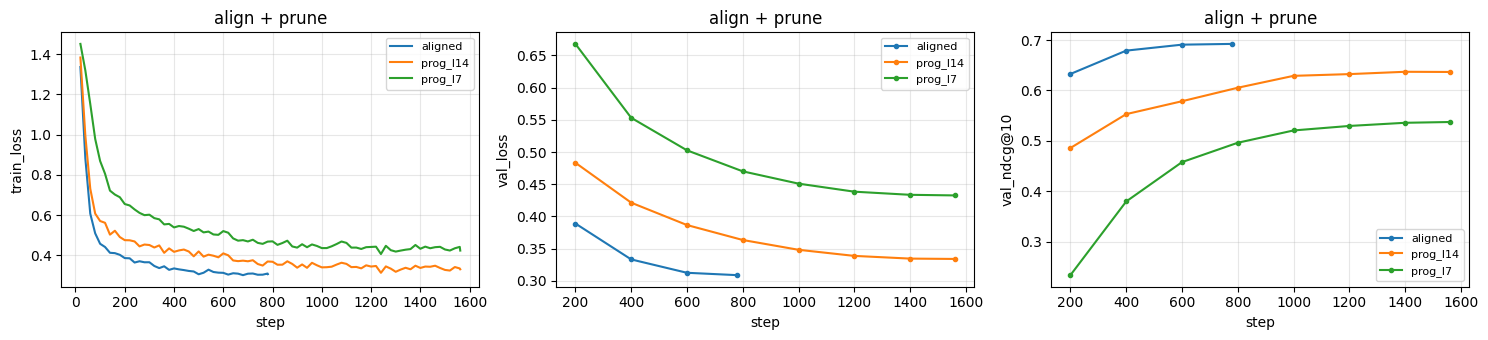

In [7]:
import matplotlib.pyplot as plt
from IPython.display import display
from run_exp import plot_curves, save_fig

fig = plot_curves({n: f"{RUN_DIR}/{n}" for n in runs}, ("train_loss", "val_loss", "val_ndcg@10"), "align + prune")
display(save_fig(fig, RUN_DIR, "align_prune_curves"))
plt.close("all")

## 5 · Retrieval quality per stage (val + test)
Student queries vs the frozen teacher corpus. retention = nDCG@10 / teacher nDCG@10.

In [8]:
from run_exp import evaluate_runs, print_rows

metrics = evaluate_runs(runs, data, index, RUN_DIR, EVAL)
for split in ("val", "test"):
    print_rows(metrics, list(runs), split)
    print()

[eval] teacher -> /kaggle/working/runs/full/metrics.json


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[eval] aligned -> /kaggle/working/runs/full/metrics.json


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[eval] prog_l14 -> /kaggle/working/runs/full/metrics.json


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[eval] prog_l7 -> /kaggle/working/runs/full/metrics.json
split=val
run                    recall@100  recall@10    ndcg@10     mrr@10  retention
teacher                    0.9937     0.9405     0.8015     0.7591     1.0000
aligned                    0.9701     0.8635     0.6926     0.6419     0.8641
prog_l14                   0.9501     0.8105     0.6370     0.5862     0.7948
prog_l7                    0.9079     0.7153     0.5371     0.4845     0.6702

split=test
run                    recall@100  recall@10    ndcg@10     mrr@10  retention
teacher                    0.9928     0.9457     0.8063     0.7639     1.0000
aligned                    0.9707     0.8636     0.6975     0.6486     0.8651
prog_l14                   0.9479     0.8136     0.6410     0.5900     0.7951
prog_l7                    0.9098     0.7253     0.5470     0.4947     0.6784



## 6 · Query latency per stage (one GPU, fp16)

In [9]:
from evaluation import measure_latency
from model import load_encoder
from teacher import free_gpu_memory

texts = data["val"]["texts"][:LATENCY["n_queries"]]
for name, path in runs.items():
    model, tok = load_encoder(path, EVAL["device"], torch.float16)
    print(f"--- {name}: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M params")
    measure_latency(model, tok, texts, EVAL["device"], T["dim"], 32, "", LATENCY["batch_sizes"])
    del model
    free_gpu_memory()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

--- aligned: 606M params
[latency] bs=1      72.209 ms/query        13.8 q/s
[latency] bs=32      2.237 ms/query       447.0 q/s


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

--- prog_l14: 376M params
[latency] bs=1      24.877 ms/query        40.2 q/s
[latency] bs=32      0.773 ms/query      1294.4 q/s


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

--- prog_l7: 266M params
[latency] bs=1      13.050 ms/query        76.6 q/s
[latency] bs=32      0.442 ms/query      2264.4 q/s
